# clock/12 — systematic goal-head evaluation on the multi-predicate setup

**Question.** Run GoalScope on a fresh `check_conditions(n: int)` implementation and ask, at each
interesting token position: *given what the model is actually implementing there, is the GoalScope
read-out a faithful description of it?*

**Pipeline (one example):**
1. **Generate** the implementation — cut the prompt at `def check_conditions(n: int):\n`, greedy-decode
   the body `    a = …\n    b = …\n    c = …` (letters naming).
2. **Part (i) — oracle spans.** `label_generation` (cf. `01_data §3`) segments the generation into
   per-condition token spans + the condition description (`step_text`). This is the **truth**.
3. **GoalScope read-outs.** `apply_goalscope` → one verbalization per code token.
4. **Anchor positions.** Per assignment line: `VAR` (`a`/`b`/`c`), `=`, `indent` (line's leading
   whitespace, "−1"), `prev_end` (newline ending the previous line, "−2").
5. **Part (ii) — scoring** (truth = the implementation, not the read-out):
   - **soft** (reference = the *condition description*): graded oracle faithfulness `read-out ↔ step_text`
     — the analog of `09 §6`.
   - **hard** (reference = the *implementation span*): oracle YES/NO/MALFORMED `read-out ↔ gen_code`
     — the analog of `09 §7`, roles swapped.
6. **Scale-up preview.** A few examples → faithfulness aggregated **by anchor type**, previewing the
   grid the eventual script sweeps: `{heads, alpha, replace/additive, layer_range}`.

Everything below reuses existing code (`condition_data`, `multistep_label`, `goalscope`,
`oracle_llms`); nothing here is a new parallel implementation.

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys, re, json, random, logging
sys.path.append("../..")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "2,4")
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from rich.console import Console
from rich.theme import Theme
from rich.table import Table
from rich.text import Text
from rich.markup import escape
from src.utils import logging_utils, env_utils
logging_utils.configure(level=logging.INFO)
logger = logging.getLogger(__name__)
console = Console(theme=Theme({"default": "white"}), highlight=False)
def rich_print(*a, **k): console.print(*a, **k)

In [2]:
from src.models import ModelandTokenizer
MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"
mt = ModelandTokenizer(model_key=MODEL_NAME, dtype=torch.bfloat16,
                       device_map="auto", attn_implementation="eager")
N_LAYER = mt.n_layer
N_HEADS = mt.model.config.num_attention_heads
print(f"n_layer={N_LAYER}  n_embd={mt.n_embd}  n_heads={N_HEADS}")

2026-08-10 23:21:20 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory: /disk/u/models
2026-08-10 23:21:21 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-10 23:21:21 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-08-10 23:21:21 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-10 23:21:21 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-08-10 23:21:21 ht

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-08-10 23:21:45 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-08-10 23:21:45 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-08-10 23:21:45 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64  n_embd=5120  n_heads=40


## 1. Head sets + GoalScope config

`goal_heads` = trained mask @0.9, 32B band 25–55 (as in `09.1`/`11`). `GOALSCOPE_CONFIG` holds the
knobs the grid-search script will sweep — here we fix one config and vary only the corpus.

In [3]:
from src.goals.head_loc_attn import HeadMask

# ── goal heads (trained mask @0.9, 32B band 25-55) — copied from 11 cell 4 ──
GOAL_THRESHOLD = 0.9
GOAL_BAND = (25, 56)
gck = torch.load(os.path.join(env_utils.DEFAULT_RESULTS_DIR,
                 f"localization/{MODEL_NAME.split('/')[-1]}/lam20/head_mask.pt"), map_location="cpu")
goal_layers = [int(x) for x in gck["layers"]]
gmask = gck["mask_values"].numpy().copy()
gmask[:GOAL_BAND[0]] = 0; gmask[GOAL_BAND[1]:] = 0
goal_heads = [(goal_layers[li], int(h)) for li, h in np.argwhere(gmask > GOAL_THRESHOLD)]
print(f"goal heads (@{GOAL_THRESHOLD}, band {GOAL_BAND[0]}-{GOAL_BAND[1]-1}): {len(goal_heads)}")

goal heads (@0.9, band 25-55): 122


In [15]:
# ── the GoalScope design point (grid axes for the eventual script) ──
GOALSCOPE_CONFIG = dict(
    selected_heads   = goal_heads,                  # <-- grid: which head set
    # strategy         = "additive", alpha=0.2,       # <-- grid: "additive" | "replace"
    # strategy         = "replace", alpha=1.0,
    strategy         = "additive_norm", alpha=0.1,     # <-- grid: "additive" | "replace" | "normalized"
    steer_layer_range= (35, 46),                    # <-- grid: additive-only injection layers
    n_steer_tokens   = "all",
    max_new_tokens   = 64,
)
print(GOALSCOPE_CONFIG)

{'selected_heads': [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29), (48, 31), (48, 32), (48, 34), (49, 6), (49, 9), (49, 10), (49, 12), (49, 13), (49, 14), (49, 24), (49, 30), (49, 35), (49, 36), (49, 38), (49, 39), (50, 16), (50, 18), (50, 25), (50, 26), (51,

## 2. Corpus — `check_conditions(n: int)` with letters naming

Single-line-capable INT predicates so each condition is a clean one-liner `    a = <expr>`; letters
naming (`a`/`b`/`c`) matches how the goal heads were localized. We cut at the stub and greedy-decode
the whole body.

In [5]:
from src.goals.condition_data import (INT_PREDICATES, sample_specs, materialize)
from src.goals.functional import apply_chat_template, supports_chat_template
from src.tokens import prepare_input
from src.goals.goalscope import greedy_continue

N_SPECS, NUM_CONDITIONS, SEED = 16, [3, 4, 5], 1123
_sl_preds = [p for p in INT_PREDICATES if p.has_singleline_for("python")]
print(f"{len(_sl_preds)}/{len(INT_PREDICATES)} INT predicates have a single-line python form")

_specs = sample_specs(N_SPECS, NUM_CONDITIONS, seed=SEED, predicates=_sl_preds, allow_repeats=False)
for j, sp in enumerate(_specs): sp.spec_id = f"eval_int_{j:02d}"
samples = materialize(_specs, langs=["python"], modularities=["monolithic"])
print(f"{len(samples)} samples:", [(s.spec.spec_id, s.spec.num_conditions) for s in samples])

def build_prompt(sample):
    instr = sample.render_instruction(name_rule="letters", multistep=False)   # mandates a/b/c
    stub  = sample.render_code_stub()                                          # def check_conditions(n: int):\n
    if supports_chat_template(mt):
        return apply_chat_template(mt=mt, user_query=instr.strip(), incomplete_code=stub)
    return instr + "\nAnswer:\n" + stub

print("\n" + "=" * 30 + " one prompt " + "=" * 30)
print(build_prompt(samples[0]))

23/23 INT predicates have a single-line python form
16 samples: [('eval_int_00', 4), ('eval_int_01', 4), ('eval_int_02', 4), ('eval_int_03', 4), ('eval_int_04', 3), ('eval_int_05', 4), ('eval_int_06', 3), ('eval_int_07', 4), ('eval_int_08', 5), ('eval_int_09', 4), ('eval_int_10', 3), ('eval_int_11', 5), ('eval_int_12', 3), ('eval_int_13', 3), ('eval_int_14', 5), ('eval_int_15', 5)]

============================== one prompt ==============================
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the following conditions:

1. n is a triangular number
2. the sum of n's digits is divisible by 3
3. the sum of n's digits is greater than 20
4. n is positive

For each condition, in the order listed, assign t

In [6]:
# greedy-decode the body for every sample (single pass each; keep it small for the sketch)
completions = {}
for s in samples:
    prompt = build_prompt(s)
    inp = prepare_input(prompts=prompt, tokenizer=mt)
    completions[s.spec.spec_id] = greedy_continue(mt, **inp, max_new_tokens=256)

for s in samples:
    rich_print(f"\n[bold cyan]== {s.spec.spec_id}  preds={s.spec.predicate_ids} ==[/bold cyan]")
    rich_print(f"[grey58]{escape(' | '.join(s.spec.spec_texts))}[/grey58]")
    rich_print(f"[salmon1]{escape(s.render_code_stub() + completions[s.spec.spec_id])}[/salmon1]")

== eval_int_00  preds=['triangular', 'digit_sum_divisible', 'digit_sum_gt', 'positive'] ==

n is a triangular number | the sum of n's digits is divisible by 3 | the sum of n's digits is greater than 20 | n 
is positive

def check_conditions(n: int):
    a = (lambda x: int((x * 2) ** 0.5) ** 2 == x * 2)(n)
    b = sum(int(digit) for digit in str(n)) % 3 == 0
    c = sum(int(digit) for digit in str(n)) > 20
    d = n > 0
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, Condition 4: {d}, All conditions: {a and b and c 
and d}")
</code>

== eval_int_01  preds=['positive', 'divisible', 'digit_product_gt', 'palindrome'] ==

n is positive | n is divisible by 16 | the product of n's digits is greater than 20 | n is a palindrome (its digits
read the same forwards and backwards)

def check_conditions(n: int):
    a = n > 0
    b = n % 16 == 0
    c = eval('*'.join(str(d) for d in str(n))) > 20
    d = str(n) == str(n)[::-1]
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, Condition 4: {d}, All conditions: {a and b and c 
and d}")
</code>

... (38 outputs left out)

def check_conditions(n: int):
    a = sum(i for i in range(1, n) if n % i == 0) > n
    b = n >= 50
    c = n % 2 == 1
    d = bin(n).count('1') > 1
    e = all(int(digit) % 2 == 0 for digit in str(n))
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, Condition 4: {d}, Condition 5: {e}, All 
conditions: {a and b and c and d and e}")
</code>

== eval_int_15  preds=['positive', 'digit_sum_gt', 'le_bound', 'abundant', 'prime'] ==

n is positive | the sum of n's digits is greater than 10 | n is less than or equal to 50 | the sum of n's proper 
divisors is greater than n | n is a prime number

def check_conditions(n: int):
    a = n > 0
    b = sum(int(digit) for digit in str(n)) > 10
    c = n <= 50
    d = sum(i for i in range(1, n) if n % i == 0) > n
    e = all(n % i != 0 for i in range(2, int(n**0.5) + 1)) if n > 1 else False
    print(f"a: {a}, b: {b}, c: {c}, d: {d}, e: {e}, all: {a and b and c and d and e}")
</code>

## 3. Part (i) — oracle span labelling  *(which tokens implement which condition)*

`label_generation` (Claude oracle) segments the generation into per-condition spans — `gen_token_range`
(the implementation span) and `step_text` (the condition description). Renderer copied from `01_data §3`.

In [7]:
from src.goals.multistep_label import label_generation

PALETTE = ["green", "cyan", "magenta", "yellow", "blue", "bright_red",
           "bright_cyan", "bright_magenta", "bright_green"]
def _vis(s): return s.replace("\n", "↵\n").replace("\t", "⇥")

def render_oracle_labels(lab):
    combined = lab.full_prompt + lab.generation
    enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
    ids = enc["input_ids"]; offs = [tuple(p) for p in enc["offset_mapping"]]
    char_off = len(lab.full_prompt)
    gen_start = next(j for j, (a, b) in enumerate(offs) if a >= char_off and b > a)
    gen_step, seg_start = {}, {}
    for i, sl in enumerate(lab.labels):
        if sl.gen_token_range:
            for t in range(*sl.gen_token_range): gen_step[t] = i
            seg_start.setdefault(sl.gen_token_range[0], i)
    sty = lambda i: f"black on {PALETTE[i % len(PALETTE)]}"
    txt = Text()
    for t in range(len(ids)):
        if t == gen_start:
            txt.append("\n" + "─" * 20 + " GENERATION " + "─" * 20 + "\n", style="bold grey42")
        if t in seg_start:
            txt.append(f"\n┌── cond {seg_start[t]} ──\n", style="bold yellow")
        s = _vis(mt.tokenizer.decode([ids[t]]))
        i = gen_step.get(t) if t >= gen_start else None
        txt.append(s, style=(sty(i) if i is not None else ("grey42" if t < gen_start else "grey58")))
    console.print(txt)
    tb = Table(title="oracle step labels", show_lines=True)
    for col, w in [("cond", 4), ("condition", 40), ("gen tok", 12), ("gen_code", 44)]:
        tb.add_column(col, overflow="fold", max_width=w)
    for i, sl in enumerate(lab.labels):
        tb.add_row(str(i), sl.step_text, str(sl.gen_token_range), _vis(sl.gen_code))
    console.print(tb)

# label every sample (cached); keep the LabeledGeneration around for eval
labels_by_id = {}
for s in samples:
    prompt = build_prompt(s)
    lab = label_generation(mt, s, prompt, completions[s.spec.spec_id], use_cache=True)
    labels_by_id[s.spec.spec_id] = lab
    print(f"labeled {s.spec.spec_id}: {len(lab.labels)} conditions")

labeled eval_int_00: 4 conditions
labeled eval_int_01: 4 conditions
labeled eval_int_02: 4 conditions
labeled eval_int_03: 4 conditions
labeled eval_int_04: 3 conditions
labeled eval_int_05: 4 conditions
labeled eval_int_06: 3 conditions
labeled eval_int_07: 4 conditions
labeled eval_int_08: 5 conditions
labeled eval_int_09: 4 conditions
labeled eval_int_10: 3 conditions
labeled eval_int_11: 5 conditions
labeled eval_int_12: 3 conditions
labeled eval_int_13: 3 conditions
labeled eval_int_14: 5 conditions
labeled eval_int_15: 5 conditions


In [8]:
render_oracle_labels(labels_by_id[samples[3].spec.spec_id])

<|im_start|>system↵
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>↵
<|im_start|>user↵
Write a Python program that implements a function `check_conditions` which, given an integer n, checks the 
following conditions:↵
↵
1. the sum of n's proper divisors is greater than n↵
2. the product of n's digits is greater than 20↵
3. n has more than 4 divisors↵
4. n is a power of two↵
↵
For each condition, in the order listed, assign the boolean result of the check to its own local variable, using 
single lowercase letters in order — `a` for the first condition, `b` for the second, and so on. After all 
conditions have been checked, use a SINGLE print statement that, using those variables, reports whether each 
condition passed individually and whether all of them passed collectively.↵
Compute each condition's boolean result inside `check_conditions` (one local variable per condition); do not define
any helper functions.↵
Do not include any comments in your code.<|im_end|>↵
<|im_start|>assistant↵
<code>↵
def check_conditions(n: int):↵

──────────────────── GENERATION ────────────────────

┌── cond 0 ──
    a = sum(i for i in range(1, n) if n % i == 0) > n↵

┌── cond 1 ──
    b = (prod := 1) and all((prod := prod * int(d)) > 0 for d in str(n)) and prod > 20↵

┌── cond 2 ──
    c = len([i for i in range(1, n + 1) if n % i == 0]) > 4↵

┌── cond 3 ──
    d = (n & (n - 1)) == 0 and n != 0↵
    print(f"Condition 1: {a}, Condition 2: {b}, Condition 3: {c}, Condition 4: {d}, All: {a and b and c and d}")↵
</code>

                                              oracle step labels                                               
┏━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ cond ┃ condition                                ┃ gen tok    ┃ gen_code                                     ┃
┡━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 0    │ the sum of n's proper divisors is        │ (247, 272) │     a = sum(i for i in range(1, n) if n % i  │
│      │ greater than n                           │            │ == 0) > n↵                                   │
│      │                                          │            │                                              │
├──────┼──────────────────────────────────────────┼────────────┼──────────────────────────────────────────────┤
│ 1    │ the product of n's digits is greater     │ (272, 307) │     b = (prod := 1) and all((prod := prod *  │
│      │ than 20                                  │            │ int(d)) > 0 for d in str(n)) and prod > 20↵  │
│      │                                          │            │                                              │
├──────┼──────────────────────────────────────────┼────────────┼──────────────────────────────────────────────┤
│ 2    │ n has more than 4 divisors               │ (307, 337) │     c = len() > 4↵                           │
│      │                                          │            │                                              │
├──────┼──────────────────────────────────────────┼────────────┼──────────────────────────────────────────────┤
│ 3    │ n is a power of two                      │ (337, 358) │     d = (n & (n - 1)) == 0 and n != 0↵       │
│      │                                          │            │                                              │
└──────┴──────────────────────────────────────────┴────────────┴──────────────────────────────────────────────┘

## 4. GoalScope read-outs per token position

`apply_goalscope` over the full `prompt + generation`. Returns one dict per code token
(`pos`, `token`, `patched_gen`). We keep the HTML viz for eyeballing and index results by `pos`.

In [9]:
def _build_single_predicate_prompt(mt: ModelandTokenizer, prefix: str = "") -> str:
    """Build the GoalScope destination prompt ("What are you doing at this line?")."""
    # messages = [
    #     {"role": "system", "content": "You are a helpful assistant proficient in programming."},
    #     {"role": "user", "content": "You are implementing a simple python function that checks for a condition on an integer input. Just write the function body, without any comments or explanations. Assume all the necessary headers/libraries are already imported."},
    #     {"role": "assistant", "content": "def check(n: int) -> bool:\n"},
    # ]
    messages = [
        {"role": "system", "content": "You are a helpful assistant proficient in programming."},
        {"role": "user", "content": "You are implementing a simple C++ function that checks for a condition. Just write the function body, without any comments or explanations. Assume all the necessary headers are already included."},
        {"role": "assistant", "content": prefix},
    ]
    try:
        return mt.tokenizer.apply_chat_template(
            messages,
            add_generation_prompt=False,
            continue_final_message=True,
            tokenize=False,
            chat_template_kwargs={"enable_thinking": False},
        )
    except TypeError:
        return mt.tokenizer.apply_chat_template(
            messages,
            add_generation_prompt=False,
            continue_final_message=True,
            tokenize=False,
        )

PREFIX = "bool check(auto value){"
goalscope_prompt = _build_single_predicate_prompt(mt, prefix=PREFIX)
rich_print(goalscope_prompt)

<|im_start|>system
You are a helpful assistant proficient in programming.<|im_end|>
<|im_start|>user
You are implementing a simple C++ function that checks for a condition. Just write the function body, without any 
comments or explanations. Assume all the necessary headers are already included.<|im_end|>
<|im_start|>assistant
bool check(auto value){

In [10]:
from src.goals.goalscope import apply_goalscope

def run_goalscope(sample, show=True):
    full_text = build_prompt(sample) + completions[sample.spec.spec_id]
    res = apply_goalscope(full_text, mt=mt, show=show, include_noncode=True, goalscope_prompt=goalscope_prompt,
                          title=f"GoalScope · {sample.spec.spec_id}", **GOALSCOPE_CONFIG)
    return full_text, {r["pos"]: r for r in res}

demo_sample = samples[3]
demo_full, demo_readouts = run_goalscope(demo_sample, show=True)
print(f"{len(demo_readouts)} scoped code positions")

GoalScope[additive_norm]:   0%|          | 0/11 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
You have set `compile_config`, but we are unable to meet the criteria for compilation. Compilation will be skipped.


404 scoped code positions


## 5. Anchor positions per assignment line

For each condition's result var, locate its assignment line `    {var} = …` in the **same
tokenization GoalScope used** (`prepare_input(full_text)` offsets) and pull four anchor tokens:

| anchor | token | intuition |
|---|---|---|
| `var` | `a` / `b` / `c` | the model names the target it is about to compute |
| `eq` | `=` | commitment point — about to emit the RHS |
| `first_impl` | first RHS token after `=` | the model has started the implementation |
| `indent` | line's leading whitespace (your "−1") | just entered the line |
| `prev_end` | newline ending the previous line (your "−2") | just finished the previous condition |

Each anchor maps to a condition `k` (matched by var name) → its oracle span + description.

In [11]:
from src.tokens import find_token_range

def _tok_at_char(offsets, cpos):
    for ti, (a, b) in enumerate(offsets):
        if a <= cpos < b: return ti
    return None

def line_anchors(full_text, offsets, var, gen_char_start):
    """Token positions of {var, eq, first_impl, indent, prev_end} for the line `    {var} = ...`
    found in full_text at/after gen_char_start. Returns {} if the line isn't found."""
    m = re.search(rf"(?m)^([ \t]*){re.escape(var)}\s*=", full_text[gen_char_start:])
    if not m: return {}
    base = gen_char_start + m.start()
    indent_c = base                                   # first whitespace char of the line
    var_c    = base + len(m.group(1))                 # where `var` starts
    eq_c     = gen_char_start + m.start() + m.group(0).rfind("=")
    prev_nl  = full_text.rfind("\n", 0, base)         # newline that ends the previous line
    out = {}
    out["var"]    = _tok_at_char(offsets, var_c)
    out["eq"]     = _tok_at_char(offsets, eq_c)
    out["first_impl"] = (out["eq"] + 1 if out["eq"] is not None and out["eq"] + 1 < len(offsets) else None)  # first RHS token after `=`
    out["indent"] = _tok_at_char(offsets, indent_c) if full_text[indent_c] in " \t" else out["var"]
    out["prev_end"] = _tok_at_char(offsets, prev_nl) if prev_nl != -1 else None
    return {k: v for k, v in out.items() if v is not None}

def anchors_for_sample(sample, full_text):
    """list of dicts: {cond, var, condition, impl_span, anchors:{name->pos}}."""
    lab = labels_by_id[sample.spec.spec_id]
    enc = prepare_input(prompts=full_text, tokenizer=mt, return_offsets_mapping=True)
    offsets = [tuple(p) for p in enc.pop("offset_mapping")[0].tolist()]
    gen_char_start = len(build_prompt(sample))
    # var name per condition (letters): a, b, c, ... in order
    out = []
    for k, sl in enumerate(lab.labels):
        var = chr(97 + k)
        a = line_anchors(full_text, offsets, var, gen_char_start)
        out.append(dict(cond=k, var=var, condition=sl.step_text,
                        impl_span=sl.gen_code.strip(), anchors=a))
    return out, offsets

demo_anchors, demo_offsets = anchors_for_sample(demo_sample, demo_full)
_at = Table(title=f"anchors · {demo_sample.spec.spec_id}", show_lines=True)
for c in ["cond", "var", "anchor", "pos", "token", "read-out"]:
    _at.add_column(c, overflow="fold", max_width=(48 if c == "read-out" else 20))
for row in demo_anchors:
    for aname, pos in row["anchors"].items():
        ro = demo_readouts.get(pos, {}).get("patched_gen", "—")
        _at.add_row(str(row["cond"]), row["var"], aname, str(pos),
                    escape(_vis(demo_readouts.get(pos, {}).get("token", "?"))),
                    PREFIX + escape(ro))
rich_print(_at)

                                   anchors · eval_int_03                                    
┏━━━━━━┳━━━━━┳━━━━━━━━━━━━┳━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ cond ┃ var ┃ anchor     ┃ pos ┃ token ┃ read-out                                         ┃
┡━━━━━━╇━━━━━╇━━━━━━━━━━━━╇━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 0    │ a   │ var        │ 248 │  a    │ bool check(auto value){ return value > 0; }      │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 0    │ a   │ eq         │ 249 │  =    │ bool check(auto value){ return value > 10; }     │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 0    │ a   │ first_impl │ 250 │  sum  │ bool check(auto value){ int sum = 0; for(int i = │
│      │     │            │     │       │ 1; i <= value / 2; ++i) if(value % i == 0) sum   │
│      │     │            │     │       │ += i; return sum > value && value != 1; }        │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 0    │ a   │ indent     │ 247 │       │ bool check(auto value){                          │
│      │     │            │     │       │     bool isDivisible = false;                    │
│      │     │            │     │       │     for(int i = 1; i < value; ++i){              │
│      │     │            │     │       │         if(value % i == 0) isDivisible |= true;  │
│      │     │            │     │       │     }                                            │
│      │     │            │     │       │     return isDivisible && (value % 2 == 0);      │
│      │     │            │     │       │ }                                                │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 0    │ a   │ prev_end   │ 246 │ ):↵   │ bool check(auto value){ return value > 0 &&      │
│      │     │            │     │       │ value < 10; }                                    │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ var        │ 273 │  b    │ bool check(auto value){ return value > 10 &&     │
│      │     │            │     │       │ value % 2 == 0; }                                │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ eq         │ 274 │  =    │ bool check(auto value){ return value > 10; }     │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ first_impl │ 275 │  (    │ bool check(auto value){ int product = 1;         │
│      │     │            │     │       │ while(value > 0) { product *= value % 10; value  │
│      │     │            │     │       │ /= 10; } return product > 1; }                   │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ indent     │ 272 │       │ bool check(auto value){ return (value > 0) &&    │
│      │     │            │     │       │ (value % 10 != 0) && ((value / 10) % 10 != 0) && │
│      │     │            │     │       │ ((value / 100) % 10 != 0) && ((value / 1000) % 1 │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 1    │ b   │ prev_end   │ 271 │ ↵     │ bool check(auto value){ return value > 0 &&      │
│      │     │            │     │       │ value % 2 == 0 && value % 3 != 0 && value % 5 == │
│      │     │            │     │       │ 0; }                                             │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 2    │ c   │ var        │ 308 │  c    │ bool check(auto value){ return value > 2; }      │
├──────┼─────┼────────────┼─────┼───────┼──────────────────────────────────────────────────┤
│ 2    │ c   │ eq         │ 309 │  =    │ bool check(auto value){ int count = 0; for(int i │
│

### 5b. Rule-based impl-span (no oracle) for `naming="letters"`

With letters naming the body is deterministic — `    a = … / b = … / c = … / print(…)` — so a
condition's implementation is just the code between its own `<letter> =` line and the **next**
letter's line (and for the last letter, up to the terminal `print`/`return`). No `label_generation`
needed. Below we compare this rule against the oracle `gen_code` spans; if agreement is high we wire
`rule_based_spans` into the eval script to drop the oracle span-labelling step.

> Why? To save some money on API calls.

In [12]:
def rule_based_spans(full_text, gen_char_start, n_conditions):
    """Per-condition impl_span for naming="letters", purely rule-based.
    span[k] = code between `<letter_k> =` and the next present `<letter> =` line; for the last
    present letter, up to the terminal print/return. Returns list[str|None] (None if not found)."""
    gen = full_text[gen_char_start:]
    starts = []
    for k in range(n_conditions):
        letter = chr(97 + k)
        m = re.search(rf"(?m)^[ \t]*{re.escape(letter)}\s*=(?!=)", gen)   # assignment, not `==`
        starts.append(m.start() if m else None)
    present = [s for s in starts if s is not None]
    if not present:
        return [None] * n_conditions
    last_start = max(present)
    mterm = re.search(r"(?m)^[ \t]*(?:print|return)\b", gen[last_start:])  # terminal statement
    term = last_start + mterm.start() if mterm else len(gen)
    spans = []
    for k in range(n_conditions):
        s = starts[k]
        if s is None:
            spans.append(None); continue
        later = [t for t in starts[k + 1:] if t is not None and t > s]
        e = min(later) if later else term
        spans.append(gen[s:e].strip())
    return spans

In [13]:
# ── rule-based vs oracle impl_span, over all samples ──
def _norm(s): return re.sub(r"\s+", " ", (s or "").strip())

_ct = Table(title="rule-based vs oracle impl_span (naming='letters')", show_lines=True)
for c in ["spec", "cond", "var", "rule-based span", "oracle span", "match"]:
    _ct.add_column(c, overflow="fold", max_width=(30 if "span" in c else 12))
n_match = n_tot = 0
for s in samples:
    prompt = build_prompt(s)
    ft = prompt + completions[s.spec.spec_id]
    lab = labels_by_id[s.spec.spec_id]
    rspans = rule_based_spans(ft, len(prompt), len(lab.labels))
    for k, sl in enumerate(lab.labels):
        rb, orc = rspans[k], sl.gen_code.strip()
        m = _norm(rb) == _norm(orc)
        n_tot += 1; n_match += int(m)
        _ct.add_row(s.spec.spec_id, str(k), chr(97 + k),
                    escape(_vis(rb or "—")), escape(_vis(orc)),
                    "[green]OK[/green]" if m else "[red]DIFF[/red]")
rich_print(_ct)
print(f"exact-match (whitespace-normalized): {n_match}/{n_tot} = {n_match/max(n_tot,1):.0%}")

                          rule-based vs oracle impl_span (naming='letters')                           
┏━━━━━━━━━━━━━┳━━━━━━┳━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ spec        ┃ cond ┃ var ┃ rule-based span                ┃ oracle span                    ┃ match ┃
┡━━━━━━━━━━━━━╇━━━━━━╇━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ eval_int_00 │ 0    │ a   │ a = (lambda x: int((x * 2) **  │ a = (lambda x: int((x * 2) **  │ OK    │
│             │      │     │ 0.5) ** 2 == x * 2)(n)         │ 0.5) ** 2 == x * 2)(n)         │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_00 │ 1    │ b   │ b = sum(int(digit) for digit   │ b = sum(int(digit) for digit   │ OK    │
│             │      │     │ in str(n)) % 3 == 0            │ in str(n)) % 3 == 0            │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_00 │ 2    │ c   │ c = sum(int(digit) for digit   │ c = sum(int(digit) for digit   │ OK    │
│             │      │     │ in str(n)) > 20                │ in str(n)) > 20                │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_00 │ 3    │ d   │ d = n > 0                      │ d = n > 0                      │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_01 │ 0    │ a   │ a = n > 0                      │ a = n > 0                      │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_01 │ 1    │ b   │ b = n % 16 == 0                │ b = n % 16 == 0                │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_01 │ 2    │ c   │ c = eval('*'.join(str(d) for d │ c = eval('*'.join(str(d) for d │ OK    │
│             │      │     │ in str(n))) > 20               │ in str(n))) > 20               │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_01 │ 3    │ d   │ d = str(n) == str(n)[::-1]     │ d = str(n) == str(n)[::-1]     │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_02 │ 0    │ a   │ a = int(n**0.5)**2 == n        │ a = int(n**0.5)**2 == n        │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_02 │ 1    │ b   │ b = n % 2 != 0 and n % 3 != 0  │ b = n % 2 != 0 and n % 3 != 0  │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_02 │ 2    │ c   │ c = n > 0                      │ c = n > 0                      │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_02 │ 3    │ d   │ d = n >= 100                   │ d = n >= 100                   │ OK    │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_03 │ 0    │ a   │ a = sum(i for i in range(1, n) │ a = sum(i for i in range(1, n) │ OK    │
│             │      │     │ if n % i == 0) > n             │ if n % i == 0) > n             │       │
├─────────────┼──────┼─────┼────────────────────────────────┼────────────────────────────────┼───────┤
│ eval_int_03 │ 1    │ b   │ b = (prod := 1) and all((prod  │ b = (prod := 1) and all((prod  │ OK    │
│             │      │     │ := prod * int(d)) > 0 for d in │ := prod * int(d)) > 0 for d in │       │
│             │      │     │ str(n)) and prod > 20          │ str(n)) and prod > 20          │       │
├─────────────┼──────┼─────┼────────────────────────────────┼─────────────────────────

exact-match (whitespace-normalized): 63/63 = 100%


## 6. Soft eval — closed-set **likelihood over the full patched readout** (no oracle)
<text style="color:red">**DOESN'T WORK**</text>

The patch's influence plays out over the *whole* autoregressive generation, so we score the actual
`max_new_tokens` readout GoalScope produces (identical to the viz) instead of teacher-forcing a short
reference at the answer-start — where the goal signal barely moves the first token, which is why the
earlier keyword-LL diverged from the viz and hard-eval.

`soft_from_readout` computes, non-oracle, the model's closed-set likelihood `p(reference_k | readout)`
over all predicates and reports `p_true` for the predicate the code implements (`spec.predicate_ids[k]`).
Because it reads the *same* generated text hard-eval reads, the two now track each other; the patch's
influence is identical to the viz because it **is** the viz generation.

`candidate_lls_under_patch` (teacher-forcing a short reference *under the patch*) is kept as a direct
signal probe — the demo prints both side by side so you can see the gap. Candidate text still comes
from `id_substrs` (placeholders stripped); `REF_SOURCE="spec"` is available.

In [ ]:
# ── §6: likelihood-based soft eval — closed set over ALL predicates, under the GoalScope patch ──
import baukit
from src.goals.head_loc_attn import collect_head_steering_vecs
from src.goals.goalscope import _build_goalscope_prompt

REF_SOURCE = "id_substrs"  # "id_substrs" (placeholders stripped) | "spec" (spec_template, stripped)


def predicate_reference_text(pred, source=REF_SOURCE):
    if source == "spec":
        t = re.sub(r"\{[^}]*\}", "", pred.spec_template)
        return re.sub(r"\s+", " ", t).strip(" .")
    return " ".join(s for s in pred.id_substrs if "{" not in s)  # drop {a}/{b}/{k}/{t}


# candidate set = every predicate of the working datatype (int), fixed order
ALL_PREDS = INT_PREDICATES
PRED_IDS = [p.id for p in ALL_PREDS]
PRED_REF = [predicate_reference_text(p) for p in ALL_PREDS]
PRED_TOK = [
    mt.tokenizer(" " + t, add_special_tokens=False)["input_ids"] for t in PRED_REF
]  # leading space = continues the answer
_PROBE_IDS = prepare_input(prompts=_build_goalscope_prompt(mt), tokenizer=mt)[
    "input_ids"
][0].tolist()
print(
    f"{len(ALL_PREDS)} candidate predicates (REF_SOURCE={REF_SOURCE!r}); e.g.",
    list(zip(PRED_IDS[:5], PRED_REF[:5])),
)


@torch.no_grad()
def candidate_lls_under_patch(steering_vec, alpha, steer_layers, length_norm=True):
    """(n_pred,) length-normalized log p of each predicate reference as the probe answer, with
    `alpha*steering_vec` added at every answer-predicting position on `steer_layers` (mirrors
    GoalScope's per-step -1 injection). One padded forward over all candidates."""
    dev = next(mt._model.parameters()).device
    P = len(_PROBE_IDS)
    seqs = [_PROBE_IDS + t for t in PRED_TOK]
    maxlen = max(len(s) for s in seqs)
    pad = (
        mt.tokenizer.pad_token_id
        if mt.tokenizer.pad_token_id is not None
        else mt.tokenizer.eos_token_id
    )
    ids = torch.full((len(seqs), maxlen), pad, dtype=torch.long)
    attn = torch.zeros((len(seqs), maxlen), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, : len(s)] = torch.tensor(s)
        attn[i, : len(s)] = 1
    ids, attn = ids.to(dev), attn.to(dev)
    sv = (alpha * steering_vec).to(dev)
    layer_names = [mt.layer_name_format.format(l) for l in steer_layers]

    def _edit(output, layer):  # baukit edit_output(output, layer)
        is_tuple = isinstance(output, tuple)
        h = output[0] if is_tuple else output
        h[:, P - 1 :, :] = h[:, P - 1 :, :] + sv.to(
            device=h.device, dtype=h.dtype
        )  # inject over the answer region
        return (h,) + output[1:] if is_tuple else h

    with baukit.TraceDict(mt._model, layer_names, edit_output=_edit):
        logits = mt._model(input_ids=ids, attention_mask=attn).logits.float()
    logp = torch.log_softmax(logits, dim=-1)  # (n, seq, vocab)

    lls = []
    for i, t in enumerate(PRED_TOK):
        pos = torch.arange(
            P - 1, P - 1 + len(t), device=logp.device
        )  # position j predicts answer token j
        tgt = torch.tensor(t, device=logp.device)
        s = logp[i, pos, tgt].sum()
        lls.append(float((s / len(t) if length_norm else s).cpu()))
    return np.array(lls)


def soft_metrics_ll(lls, true_pred_id, tau=1.0):
    lls = np.asarray(lls, float)
    p = np.exp((lls - lls.max()) / tau)
    p = p / p.sum()
    ti = PRED_IDS.index(true_pred_id)
    order = np.argsort(-lls)
    rank = int(np.where(order == ti)[0][0]) + 1
    return dict(
        p_true=float(p[ti]),
        rank_true=rank,
        argmax_id=PRED_IDS[int(order[0])],
        redirected=bool(order[0] == ti),
    )


def _readout_classifier_ctx(readout):
    msgs = [
        {"role": "user", "content":
            "A model was asked what a line of Python code is doing and answered:\n\n"
            f'"{readout.strip()}"\n\n'
            "Based only on that answer, name the single property of the number n that the code is "
            "checking. Reply with just the property."},
        {"role": "assistant", "content": ""},
    ]
    return mt.tokenizer.apply_chat_template(
        msgs, tokenize=False, add_generation_prompt=False, continue_final_message=True)

@torch.no_grad()
def soft_from_readout(readout, true_pred_id, length_norm=True):
    """Closed-set LM likelihood over the FULL patched readout: p(reference_k | readout), softmaxed
    over all predicates. Unpatched forward — the patch already shaped `readout` (== the viz gen).
    Returns a soft_metrics_ll-style dict."""
    if not readout or not readout.strip():
        return dict(p_true=float("nan"), rank_true=len(ALL_PREDS), argmax_id=None, redirected=False)
    dev = next(mt._model.parameters()).device
    ctx = prepare_input(prompts=_readout_classifier_ctx(readout), tokenizer=mt)["input_ids"][0].tolist()
    C = len(ctx)
    seqs = [ctx + t for t in PRED_TOK]
    maxlen = max(len(s) for s in seqs)
    pad = mt.tokenizer.pad_token_id if mt.tokenizer.pad_token_id is not None else mt.tokenizer.eos_token_id
    ids = torch.full((len(seqs), maxlen), pad, dtype=torch.long)
    attn = torch.zeros((len(seqs), maxlen), dtype=torch.long)
    for i, s in enumerate(seqs):
        ids[i, :len(s)] = torch.tensor(s); attn[i, :len(s)] = 1
    logits = mt._model(input_ids=ids.to(dev), attention_mask=attn.to(dev)).logits.float()
    logp = torch.log_softmax(logits, dim=-1)
    lls = []
    for i, t in enumerate(PRED_TOK):
        pos = torch.arange(C - 1, C - 1 + len(t), device=logp.device)
        tgt = torch.tensor(t, device=logp.device)
        lls.append(float((logp[i, pos, tgt].sum() / (len(t) if length_norm else 1)).cpu()))
    return soft_metrics_ll(np.array(lls), true_pred_id)

# demo: readout-based soft (used by the driver) vs under-patch probe, on the `eq` anchor
assert GOALSCOPE_CONFIG["strategy"] == "additive", "under-patch probe supports additive strategy only"
_demo_src = prepare_input(prompts=demo_full, tokenizer=mt)
_apos = sorted({p for row in demo_anchors for p in row["anchors"].values()})
_svs = collect_head_steering_vecs(mt, _demo_src, GOALSCOPE_CONFIG["selected_heads"], token_positions=_apos)[0]
_svby = {p: _svs[i] for i, p in enumerate(_apos)}
_slay = list(range(*GOALSCOPE_CONFIG["steer_layer_range"]))
for row in demo_anchors:
    pos = row["anchors"].get("eq")
    if pos is None:
        continue
    true_id = demo_sample.spec.predicate_ids[row["cond"]]
    ro = demo_readouts.get(pos, {}).get("patched_gen", "")
    m_read = soft_from_readout(ro, true_id)
    m_probe = soft_metrics_ll(candidate_lls_under_patch(_svby[pos], GOALSCOPE_CONFIG["alpha"], _slay), true_id)
    print(f"[{row['cond']}] true={true_id:20s} readout p_true={m_read['p_true']:.3f}(r{m_read['rank_true']},argmax={m_read['argmax_id']})"
          f"  |  probe p_true={m_probe['p_true']:.3f}(r{m_probe['rank_true']})")
    print(f"      readout: {ro[:90]!r}")


23 candidate predicates (REF_SOURCE='id_substrs'); e.g. [('positive', 'positive'), ('le_bound', 'less than or equal'), ('ge_bound', 'greater than or equal'), ('in_range', 'between'), ('even', 'even')]
[0] true=num_digits_ge        readout p_true=0.000(r6,argmax=ge_bound)  |  probe p_true=0.001(r6)
      readout: 'Checking if the number has at least two digits.'
[1] true=digit_product_gt     readout p_true=0.000(r13,argmax=le_bound)  |  probe p_true=0.001(r8)
      readout: 'Calculating the product of all digits in a number, ensuring the number has no zeros.'
[2] true=coprime_with         readout p_true=0.932(r1,argmax=coprime_with)  |  probe p_true=0.236(r2)
      readout: "I'm checking if the number is coprime with 10 by ensuring it's not divisible by 2 or 5."


## 7. Hard eval — oracle YES/NO faithfulness vs the *implementation span*

Reference = the actual code the model wrote for this condition (`gen_code`). Oracle asks: is the
read-out a faithful description of *this code*? YES / NO / MALFORMED — the analog of `09 §7`, roles
swapped (truth is the implementation). Also a closed-set K-way assignment: which of the example's
conditions does the read-out best name? (redirect / accuracy).

In [16]:
import hashlib
from src.utils.oracle_llms import ask_claude

HARD_SYS = """You are grading a lightweight interpretability probe (a patchscope). The DESCRIPTION below was read out of a model's hidden state at a SINGLE token while the model was writing one line of Python CODE that checks some property of its input. The read-out method is a steering setup on a informationless C++ function stub. Because it is squeezed out of one token, the description is usually NOISY: it may half-written code, be cut off mid-generation, be syntactically incorrect, or repeat and loop. Look PAST all of that surface noise and grade only the SUBSTANCE.

The question: does the C++ completion surface **ANYTHING GENUINELY RELEVANT** to what the CODE is doing — any relevant operation, quantity, sub-step, or property of the input? Pulling even a small correct fragment should be considered as a SUCCESS, so grade leniently.

Answer with exactly one token:
  YES        - the description contains SOME content genuinely relevant to what the code does, however partial, imprecise, or garbled.
  NO         - the description is coherent and about a specific thing, but that thing is UNRELATED to what the code does.
  NO_INFO    - the description is coherent but too generic to indicate any specific aspect of the code (e.g. just 'doing a computation on the number').
  MALFORMED  - the description is contentless: empty, pure punctuation or garbage, or repetition that carries NO relevant meaning.


The following do NOT count against the description (still YES):
  - Wrong specifics: a wrong constant, threshold, bound, modulus, operator, or comparison. If the code computes some quantity and compares it to a value, naming the quantity alone is enough and the exact value can be wrong or missing. Example: the code implements `count(word, "b") > 5`; a c++ completion counts the number of a `substr` in the `word` it should be judges as YES, even if the substr != b and/or the threshold is wrong.
  - Partial coverage: naming just one relevant ingredient of a multi-part check counts. in the example above, for `count(word, "b") > 5`, a c++ completion that only counts the number of `substr` in the `word` is still YES, even if it doesn't check the threshold.
  - Different implementation nuance: differemt implementation strategies for implementing the same idea. Example: the python code implements nth fibonacci recursively; a c++ completion implements it iteratively. This is still YES, because the underlying property being calculated is the same.
  - Broken, repetitive, or looping text, AS LONG AS the repeated content is relevant. Example: a read-out that keeps repeating the anything relevant to the correct operation is YES, not MALFORMED.

Finally, you should grade on meaning, not on shared keywords. Output only YES, NO, NO_INFO, or MALFORMED.
Put your final answer inside <verdict>{ans}</verdict> tags, with no other text or explanation, to facilitate automated parsing.
"""
_HARD_TAG = hashlib.md5(HARD_SYS.encode()).hexdigest()[:8]

_KWAY_SYS = "You match a description to the closest condition. Output only an integer."


def hard_faithfulness(readout, impl_span, use_cache=True):
    """dict(verdict, prompt, system, response). verdict in {YES, NO, NO_INFO, MALFORMED, UNPARSED}.
    `prompt`/`response` are None when the read-out is empty (no oracle call)."""
    if not readout or not readout.strip():
        return dict(verdict="MALFORMED", prompt=None, system=HARD_SYS, response=None)
    prompt = f"Python (gold): {impl_span}\nC++ (read-out): {readout.strip()}\nAnswer:"
    resp = ask_claude(prompt=prompt, system_prompt=HARD_SYS, max_tokens=256,
                      use_cache=use_cache, model_name="claude-sonnet-4-6")
    # r = resp.strip().upper()
    # verdict = next((tag for tag in ("MALFORMED", "NO_INFO", "YES", "NO") if r.startswith(tag)), "UNPARSED")
    r = re.search(r"<verdict>(.*?)</verdict>", resp, re.IGNORECASE)
    verdict = r.group(1).upper() if r else "UNPARSED"
    return dict(verdict=verdict, prompt=prompt, system=HARD_SYS, response=resp)


# def kway_assign(readout, conditions, use_cache=True):
#     """dict(pred, prompt, system, response). `pred` = matched condition index or None.
#     `prompt`/`response` are None when the read-out is empty (no oracle call)."""
#     if not readout or not readout.strip():
#         return dict(pred=None, prompt=None, system=_KWAY_SYS, response=None)
#     menu = "\n".join(f"{i}. {c}" for i, c in enumerate(conditions))
#     prompt = (f"Conditions:\n{menu}\n\nDescription: {readout.strip()}\n"
#               f"Which condition number does the description best match? Output only the integer, "
#               f"or -1 if none.")
#     resp = ask_claude(prompt=prompt, system_prompt=_KWAY_SYS, max_tokens=256,
#                       use_cache=use_cache, model_name="claude-sonnet-5")
#     m = re.search(r"-?\d+", resp)
#     pred = int(m.group()) if m else None
#     if pred is not None and not (0 <= pred < len(conditions)):
#         pred = None
#     return dict(pred=pred, prompt=prompt, system=_KWAY_SYS, response=resp)


# demo on the `eq` anchor
_conds = [r["condition"] for r in demo_anchors]
for row in demo_anchors:
    pos = row["anchors"].get("eq")
    ro = PREFIX + demo_readouts.get(pos, {}).get("patched_gen", "")
    hv = hard_faithfulness(ro, row["impl_span"], use_cache=True)
    # kv = kway_assign(ro, _conds)
    print(f"read-out={ro!r}")
    print(f"[{row['cond']}] hard(vs `{row['impl_span']}`) = {hv['verdict']}")
    # print(f"     kway->{kv['pred']} (true {row['cond']})")
    print(f"     hard oracle resp: {hv['response']!r}")
    # print(f"     kway oracle resp: {kv['response']!r}")

read-out='bool check(auto value){ return value > 10; }'
[0] hard(vs `a = sum(i for i in range(1, n) if n % i == 0) > n`) = NO
     hard oracle resp: 'The code checks if the sum of proper divisors of n is greater than n (checking if n is abundant). The C++ completion just checks if a value is greater than 10, which is unrelated to divisor sums.\n\n<verdict>NO</verdict>'
read-out='bool check(auto value){ return value > 10; }'
[1] hard(vs `b = (prod := 1) and all((prod := prod * int(d)) > 0 for d in str(n)) and prod > 20`) = NO
     hard oracle resp: "The code computes the product of digits and checks if it's > 20. The C++ completion just checks if a value > 10, which is a threshold comparison but not related to digit products.\n\n<verdict>NO</verdict>"
read-out='bool check(auto value){ int count = 0; for(int i = 1; i <= value; ++i) if(value % i == 0) ++count; return count > 2;}'
[2] hard(vs `c = len([i for i in range(1, n + 1) if n % i == 0]) > 4`) = YES
     hard oracle resp: '<verdict>

In [17]:
resp = hard_faithfulness(
    readout="bool check(int value) { root = math.pow(value, 1/3); return root * root * root == value; }",
    impl_span="n == pow(pow(n, 1/3), 3)",
    use_cache=False
)
rich_print(resp)

2026-08-10 23:31:41 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"


{
    'verdict': 'YES',
    'prompt': 'Python (gold): n == pow(pow(n, 1/3), 3)\nC++ (read-out): bool check(int value) { root = 
math.pow(value, 1/3); return root * root * root == value; }\nAnswer:',
    'system': 'You are grading a lightweight interpretability probe (a patchscope). The DESCRIPTION below was read 
out of a model\'s hidden state at a SINGLE token while the model was writing one line of Python CODE that checks 
some property of its input. The read-out method is a steering setup on a informationless C++ function stub. Because
it is squeezed out of one token, the description is usually NOISY: it may half-written code, be cut off 
mid-generation, be syntactically incorrect, or repeat and loop. Look PAST all of that surface noise and grade only 
the SUBSTANCE.\n\nThe question: does the C++ completion surface **ANYTHING GENUINELY RELEVANT** to what the CODE is
doing — any relevant operation, quantity, sub-step, or property of the input? Pulling even a small correct fragment
should be considered as a SUCCESS, so grade leniently.\n\nAnswer with exactly one token:\n  YES        - the 
description contains SOME content genuinely relevant to what the code does, however partial, imprecise, or 
garbled.\n  NO         - the description is coherent and about a specific thing, but that thing is UNRELATED to 
what the code does.\n  NO_INFO    - the description is coherent but too generic to indicate any specific aspect of 
the code (e.g. just \'doing a computation on the number\').\n  MALFORMED  - the description is contentless: empty, 
pure punctuation or garbage, or repetition that carries NO relevant meaning.\n\n\nThe following do NOT count 
against the description (still YES):\n  - Wrong specifics: a wrong constant, threshold, bound, modulus, operator, 
or comparison. If the code computes some quantity and compares it to a value, naming the quantity alone is enough 
and the exact value can be wrong or missing. Example: the code implements `count(word, "b") > 5`; a c++ completion 
counts the number of a `substr` in the `word` it should be judges as YES, even if the substr != b and/or the 
threshold is wrong.\n  - Partial coverage: naming just one relevant ingredient of a multi-part check counts. in the
example above, for `count(word, "b") > 5`, a c++ completion that only counts the number of `substr` in the `word` 
is still YES, even if it doesn\'t check the threshold.\n  - Different implementation nuance: differemt 
implementation strategies for implementing the same idea. Example: the python code implements nth fibonacci 
recursively; a c++ completion implements it iteratively. This is still YES, because the underlying property being 
calculated is the same.\n  - Broken, repetitive, or looping text, AS LONG AS the repeated content is relevant. 
Example: a read-out that keeps repeating the anything relevant to the correct operation is YES, not 
MALFORMED.\n\nFinally, you should grade on meaning, not on shared keywords. Output only YES, NO, NO_INFO, or 
MALFORMED.\nPut your final answer inside <verdict>{ans}</verdict> tags, with no other text or explanation, to 
facilitate automated parsing.\n',
    'response': '<verdict>YES</verdict>'
}

## 8. End-to-end driver + small scale-up + per-anchor summary

`eval_example` runs GoalScope once, walks every (condition, anchor), and scores soft + hard + kway.
Aggregating over a few examples answers the sketch's real question: **which anchor position yields
the most faithful read-outs?** — the row the grid-search script will later cross with
`{heads, alpha, strategy, layer_range}`.

In [18]:
ANCHOR_ORDER = ["prev_end", "indent", "var", "eq", "first_impl"]

def eval_example(sample, show=False):
    # anchors first, so GoalScope only generates at those positions (not every code token)
    full_text = build_prompt(sample) + completions[sample.spec.spec_id]
    rows_out, _ = anchors_for_sample(sample, full_text)
    conds = [r["condition"] for r in rows_out]
    apos = sorted({p for r in rows_out for p in r["anchors"].values()})
    res = apply_goalscope(full_text, mt=mt, show=show, include_noncode=False,
                          token_positions=apos, title=f"GoalScope · {sample.spec.spec_id}",
                          **GOALSCOPE_CONFIG)
    readouts = {r["pos"]: r for r in res}
    recs = []
    for row in rows_out:
        for aname, pos in row["anchors"].items():
            ro = PREFIX + readouts.get(pos, {}).get("patched_gen", "")
            hv = hard_faithfulness(ro, row["impl_span"])          # dict(verdict, prompt, system, response)
            # kv = kway_assign(ro, conds)                           # dict(pred, prompt, system, response)
            recs.append(dict(
                spec=sample.spec.spec_id, cond=row["cond"], var=row["var"], anchor=aname, pos=pos,
                readout=ro, impl_span=row["impl_span"], condition=row["condition"],
                hard=hv["verdict"], hard_prompt=hv["prompt"], hard_response=hv["response"],
                # kway_pred=kv["pred"], kway_true=row["cond"],
                # kway_prompt=kv["prompt"], kway_response=kv["response"],
            ))
    return recs

all_recs = []
for s in samples:
    all_recs += eval_example(s, show=False)
    logger.info(f"evaluated {s.spec.spec_id}")
eval_df = pd.DataFrame(all_recs)
eval_df["hard_yes"] = (eval_df.hard == "YES").astype(float)
# eval_df["kway_ok"]  = (eval_df.kway_pred == eval_df.kway_true).astype(float)
print(f"{len(eval_df)} (condition, anchor) rows over {eval_df.spec.nunique()} examples")

def show_oracle(row):
    """Pretty-print one eval_df row's full oracle exchange — for debugging/polishing the prompts."""
    r = eval_df.loc[row] if isinstance(row, int) else row
    rich_print(f"[bold]{r['spec']} · cond {r['cond']} ({r['var']}) · anchor {r['anchor']}[/bold]")
    rich_print(f"  read-out : {escape(str(r['readout']))}")
    rich_print(f"  impl_span: {escape(str(r['impl_span']))}")
    rich_print(f"  condition: {escape(str(r['condition']))}")
    rich_print(f"  [green]HARD[/green] verdict={r['hard']!r}  oracle_response={r['hard_response']!r}")
    # rich_print(f"  [yellow]KWAY[/yellow] pred={r['kway_pred']} (true {r['kway_true']})  oracle_response={r['kway_response']!r}")

# eval_df.head(12)

GoalScope[additive_norm]:   0%|          | 0/2 [00:00<?, ?it/s]

2026-08-10 23:32:06 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:07 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:08 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:11 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:12 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:14 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:16 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:19 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:21 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10

GoalScope[additive_norm]:   0%|          | 0/2 [00:00<?, ?it/s]

2026-08-10 23:32:49 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:50 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:52 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:53 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:55 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:56 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:57 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:58 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:32:59 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10

GoalScope[additive_norm]:   0%|          | 0/2 [00:00<?, ?it/s]

2026-08-10 23:33:34 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:33:35 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:33:36 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:33:38 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:33:39 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:33:44 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:33:45 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:33:49 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:33:50 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10

... (22 outputs left out)

GoalScope[additive_norm]:   0%|          | 0/2 [00:00<?, ?it/s]

2026-08-10 23:41:55 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:41:56 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:41:59 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:00 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:01 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:02 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:04 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:05 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:07 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10

GoalScope[additive_norm]:   0%|          | 0/2 [00:00<?, ?it/s]

2026-08-10 23:42:51 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:52 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:54 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:55 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:56 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:57 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:42:59 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:43:01 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10 23:43:02 httpx INFO     HTTP Request: POST https://api.anthropic.com/v1/messages "HTTP/1.1 200 OK"
2026-08-10

In [19]:
# eval_df

  faithfulness by anchor position  
          (N=16 examples,          
    config=additive_norm α=0.1)    
┏━━━━━━━━━━━━┳━━━━┳━━━━━━━━━━━━━━━┓
┃ anchor     ┃  n ┃ hard YES-rate ┃
┡━━━━━━━━━━━━╇━━━━╇━━━━━━━━━━━━━━━┩
│ prev_end   │ 63 │          0.32 │
│ indent     │ 63 │          0.60 │
│ var        │ 63 │          0.54 │
│ eq         │ 63 │          0.98 │
│ first_impl │ 63 │          0.97 │
└────────────┴────┴───────────────┘

saved /disk/u/arnab/Codes/Projects/goals/results/goal_eval/Qwen2.5-Coder-32B-Instruct/faithfulness_by_anchor.png


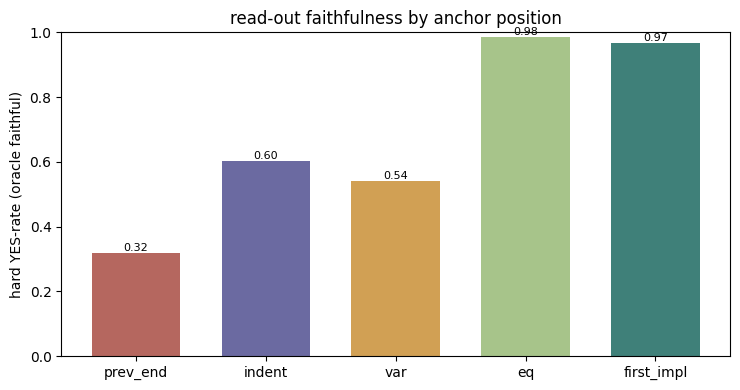

In [21]:
# ── per-anchor summary + bar plot (hard-eval + k-way; soft dropped) ──
agg = (
    eval_df.groupby("anchor")
    .agg(
        n=("hard_yes", "size"),
        hard_yes=("hard_yes", "mean"),
        # , kway_ok=("kway_ok", "mean")
    )
    .reindex([a for a in ANCHOR_ORDER if a in eval_df.anchor.unique()])
)
st = Table(
    title=f"faithfulness by anchor position (N={eval_df.spec.nunique()} examples, config={GOALSCOPE_CONFIG['strategy']} α={GOALSCOPE_CONFIG['alpha']})"
)
for c in [
    "anchor", "n", "hard YES-rate", 
    # "k-way acc"
]:
    st.add_column(c, justify=("left" if c == "anchor" else "right"))
for aname, r in agg.iterrows():
    st.add_row(
        aname, str(int(r.n)), f"{r.hard_yes:.2f}", 
        # f"{r.kway_ok:.2f}"
    )
rich_print(st)

ANCHOR_COLOR = {                       # matte / muted tones
    "prev_end": "#b5675f", "indent": "#6b6aa1", "var": "#d1a054",
    "eq": "#a7c48a", "first_impl": "#3f8079", "OVERALL": "#9a9a9a",
}
fig, ax = plt.subplots(figsize=(7.5, 4))
xs = np.arange(len(agg))
colors = [ANCHOR_COLOR.get(a, "#9a9a9a") for a in agg.index]
bars = ax.bar(xs, agg.hard_yes, 0.68, color=colors)
for r in bars:
    ax.annotate(f"{r.get_height():.2f}", (r.get_x() + r.get_width() / 2, r.get_height()),
                ha="center", va="bottom", fontsize=8)
ax.set_xticks(xs)
ax.set_xticklabels(agg.index)
ax.set_ylim(0, 1)
ax.set_ylabel("hard YES-rate (oracle faithful)")
ax.set_title("read-out faithfulness by anchor position")
plt.tight_layout()
FIGDIR = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "goal_eval", MODEL_NAME.split("/")[-1]
)
os.makedirs(FIGDIR, exist_ok=True)
FIG = os.path.join(FIGDIR, "faithfulness_by_anchor.png")
plt.savefig(FIG, dpi=110, bbox_inches="tight")
print("saved", FIG)
plt.show()

In [22]:
res = all_recs[5]
res

{'spec': 'eval_int_00',
 'cond': 1,
 'var': 'b',
 'anchor': 'var',
 'pos': 272,
 'readout': "bool check(auto value){Sure, but I need to know the specific line of code you're referring to. Please provide the code snippet or describe the condition for each part.",
 'impl_span': 'b = sum(int(digit) for digit in str(n)) % 3 == 0',
 'condition': "the sum of n's digits is divisible by 3",
 'hard': 'NO_INFO',
 'hard_prompt': "Python (gold): b = sum(int(digit) for digit in str(n)) % 3 == 0\nC++ (read-out): bool check(auto value){Sure, but I need to know the specific line of code you're referring to. Please provide the code snippet or describe the condition for each part.\nAnswer:",
 'hard_response': 'The code checks if the sum of digits of n is divisible by 3. The C++ read-out is essentially asking for clarification and contains no relevant content about digit sum or divisibility.\n\n<verdict>NO_INFO</verdict>'}

In [24]:
# res = [r for r in all_recs if r['anchor']=='eq' and r['kway_true']!=r['kway_pred']][0]
# res

In [ ]:
rich_print(res["kway_prompt"])

Conditions:
0. n has more than 1 ones in its binary representation
1. the sum of n's proper divisors is greater than n
2. n is a power of two
3. n is a perfect square

Description: I am checking if the number is a power of two by using the expression `n & (n - 1) == 0` and ensuring 
`n > 0` with `n & (n - 1) == n`.
Which condition number does the description best match? Output only the integer, or -1 if none.

In [ ]:
ask_claude(
    prompt=res["kway_prompt"], system_prompt=_KWAY_SYS, max_tokens=32,
)

'The description mentions checking if a number is a power of two using `n & (n - 1) == 0` and `n > 0'

## 9. Parsing saved runs — `scripts.evaluation.faithfulness_io`

The consolidated eval lives in `scripts/evaluation/run_goalscope_faithfulness.py` (this notebook is the
sketch). Run it from a shell, e.g.

```bash
conda run -n goals python scripts/evaluation/run_goalscope_faithfulness.py \
    --heads goal --strategy additive --alpha 0.2 --steer_layer_range 35 46 \
    --n_steer_tokens all --max_new_tokens 64
```

It saves everything (config + selected heads, per-anchor records **with the raw oracle prompts and
responses**, per-anchor summary, per-sample generations + labels) under
`results/evaluation/goalscope/faithfulness/<strategy>/<alpha>/<leaf>/`. Parse it with `faithfulness_io`:

In [3]:
from scripts.evaluation import faithfulness_io as fio

RES = env_utils.DEFAULT_RESULTS_DIR
runs = fio.list_runs(RES)
print(f"{len(runs)} saved run(s):")
for d in runs:
    print("  ", d.relative_to(fio.faithfulness_root(RES)))

if runs:
    run = fio.load_run(runs[-1])                          # dict(config, records, summary, samples, dir)
    print("\nconfig:", {k: run["config"][k] for k in
          ("heads_name", "strategy", "alpha", "steer_layer_range", "n_steer_tokens", "max_new_tokens", "n_heads")})

    # per-anchor faithfulness for this run
    rich_print(fio.summary_df(runs[-1]).to_string(index=False))

    # full records incl. raw oracle prompt+response — for polishing the system prompts
    recs = run["records"]
    print(f"\n{len(recs)} records; columns: {list(recs.columns)}")
    for _, r in recs[recs.hard != "YES"].head(3).iterrows():
        rich_print(f"[bold]{r['spec']} · {r['anchor']}[/bold]  hard={r['hard']}  kway={r['kway_pred']}/{r['kway_true']}")
        rich_print(f"   read-out : {escape(str(r['readout'])[:120])}")
        rich_print(f"   impl_span: {escape(str(r['impl_span']))}")
        rich_print(f"   hard resp: {escape(str(r['hard_response']))}")

# sweep every run's per-anchor summary (grid over design choices: heads/alpha/strategy/...)
fio.grid_df(RES)

2 saved run(s):
   additive/0.2/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123
   replace/1/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123

config: {'heads_name': 'goal', 'strategy': 'replace', 'alpha': 1.0, 'steer_layer_range': [35, 46], 'n_steer_tokens': 'all', 'max_new_tokens': 64, 'n_heads': 122}


anchor strategy  alpha heads_name  n_heads steer_layer_range n_steer_tokens  max_new_tokens  seed    n  
hard_yes  kway_ok
  prev_end  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.274877 0.222660
    indent  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.617734 0.530049
       var  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.515271 0.486700
        eq  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.966502 0.887685
first_impl  replace    1.0       goal      122          [35, 46]            all              64   123 1015  
0.943842 0.878818
   OVERALL  replace    1.0       goal      122          [35, 46]            all              64   123 5075  
0.663645 0.601182


5075 records; columns: ['spec', 'cond', 'var', 'anchor', 'pos', 'readout', 'impl_span', 'condition', 'true_pred_id', 'hard', 'hard_prompt', 'hard_response', 'kway_pred', 'kway_true', 'kway_prompt', 'kway_response']


eval_int_00 · var  hard=NO_INFO  kway=nan/0

read-out : Checking if a variable is true.

impl_span: a = round(n ** (1/3)) ** 3 == n

... (6 outputs left out)

read-out : Checking if a variable meets a condition.

impl_span: b = n >= 10

hard resp: NO_INFO

,anchor,strategy,alpha,heads_name,n_heads,steer_layer_range,n_steer_tokens,max_new_tokens,seed,n,hard_yes,kway_ok
0,prev_end,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.515271,0.262069
1,indent,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.813793,0.564532
2,var,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.749754,0.579310
3,eq,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.993103,0.927094
4,first_impl,additive,0.2,goal,122,"[35, 46]",all,64,123,1015,0.993103,0.901478
5,OVERALL,additive,0.2,goal,122,"[35, 46]",all,64,123,5075,0.813005,0.646897
6,prev_end,replace,1.0,goal,122,"[35, 46]",all,64,123,1015,0.274877,0.222660
7,indent,replace,1.0,goal,122,"[35, 46]",all,64,123,1015,0.617734,0.530049
8,var,replace,1.0,goal,122,"[35, 46]",all,64,123,1015,0.515271,0.486700
9,eq,replace,1.0,goal,122,"[35, 46]",all,64,123,1015,0.966502,0.887685


plotting: additive/0.2/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123


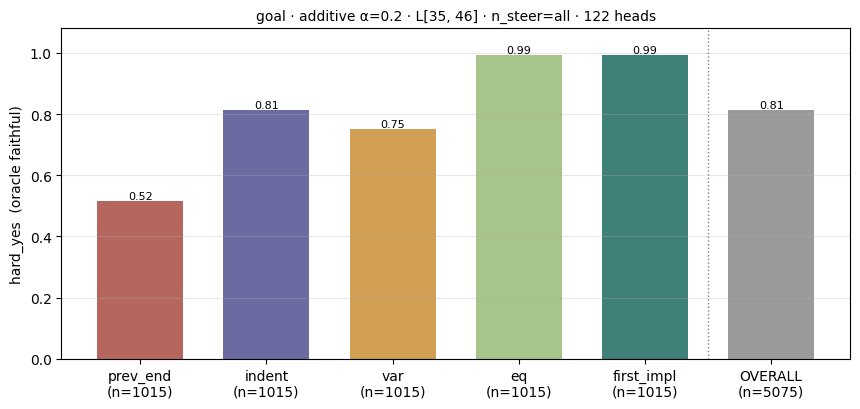

In [71]:
# ── plot one saved run: per-anchor faithfulness (hard_yes), one matte-colored bar per anchor ──
import numpy as np
import matplotlib.pyplot as plt
from scripts.evaluation import faithfulness_io as fio

RES = env_utils.DEFAULT_RESULTS_DIR
ANCHOR_ORDER = ["prev_end", "indent", "var", "eq", "first_impl"]
ANCHOR_COLOR = {                       # matte / muted tones
    "prev_end":   "#b5675f",           # reddish
    "indent":     "#6b6aa1",           # blue / violet
    "var":        "#d1a054",           # yellow / orange
    "eq":         "#a7c48a",           # light green
    "first_impl": "#3f8079",           # teal / dark green
    "OVERALL":    "#9a9a9a",           # neutral grey
}


def plot_run(run_name, res=RES):
    """run_name = path under the faithfulness root (e.g. 'additive/0.2/<leaf>', as printed by
    fio.list_runs). One matte-colored bar of hard_yes per anchor, with OVERALL split off."""
    run_dir = fio.faithfulness_root(res) / run_name
    cfg, summ = fio.load_config(run_dir), fio.load_summary(run_dir)

    anchors = [a for a in ANCHOR_ORDER if a in summ["by_anchor"]]
    hard = [summ["by_anchor"][a]["hard_yes"] for a in anchors]
    ns   = [summ["by_anchor"][a]["n"] for a in anchors]
    labels = anchors + ["OVERALL"]                       # OVERALL appended on the right
    hard  += [summ["overall"]["hard_yes"]]
    ns    += [summ.get("n_records")]
    colors = [ANCHOR_COLOR.get(a, "#9a9a9a") for a in labels]

    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(1.2 * len(labels) + 1.5, 4.2))
    bars = ax.bar(x, hard, 0.68, color=colors)
    for r in bars:
        ax.annotate(f"{r.get_height():.2f}", (r.get_x() + r.get_width() / 2, r.get_height()),
                    ha="center", va="bottom", fontsize=8)
    ax.axvline(len(anchors) - 0.5, color="grey", ls=":", lw=1)     # divider before OVERALL
    ax.set_xticks(x); ax.set_xticklabels([f"{a}\n(n={n})" for a, n in zip(labels, ns)])
    ax.set_ylim(0, 1.08); ax.set_ylabel("hard_yes  (oracle faithful)"); ax.grid(axis="y", alpha=0.3)
    title = (f"{cfg.get('heads_name')} \u00b7 {cfg.get('strategy')} \u03b1={cfg.get('alpha')} \u00b7 "
             f"L{cfg.get('steer_layer_range')} \u00b7 n_steer={cfg.get('n_steer_tokens')} \u00b7 "
             f"{cfg.get('n_heads')} heads")
    ax.set_title(title, fontsize=10)
    fig.tight_layout(); plt.show()
    return run_dir


# example: plot the most recent run (pass any run_name from fio.list_runs above)
_runs = fio.list_runs(RES)
if _runs:
    _name = str(_runs[0].relative_to(fio.faithfulness_root(RES)))
    print("plotting:", _name)
    plot_run(_name)
else:
    print("no saved faithfulness runs found under", fio.faithfulness_root(RES))


In [5]:
runs

[PosixPath('/disk/u/arnab/Codes/Projects/goals/results/evaluation/goalscope/faithfulness/additive/0.2/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123'),
 PosixPath('/disk/u/arnab/Codes/Projects/goals/results/evaluation/goalscope/faithfulness/replace/1/heads=goal__layers=35-46__nsteer=all__maxnew=64__span=rule__dtype=int__nspec=256__nc=3-4-5__seed=123')]